# Project 9: Optimizer Comparison Using a Neural Network

### Objective
Build a simple neural network using the Iris classification dataset and compare two commonly used optimization algorithms: **Stochastic Gradient Descent (SGD)** and **Adam**.

> **Note:** This version uses scikit-learn's `MLPClassifier` instead of TensorFlow/Keras. This avoids TensorFlow native DLL issues on Windows while still implementing a real neural network with both SGD and Adam optimizers.

## Task 1: Load and Prepare the Iris Dataset

The Iris dataset contains 150 samples, four numerical features, and three flower classes.

We will:
1. Load the dataset.
2. Split it into training and testing sets.
3. Standardize the input features.
4. Use the same data and network architecture for both optimizers.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Number of classes:", len(np.unique(y)))

Training samples: 120
Testing samples: 30
Number of features: 4
Number of classes: 3


## Build the Neural Network

We use the same neural network architecture for both experiments:

- Input layer: 4 features
- Hidden layer 1: 16 neurons
- Hidden layer 2: 8 neurons
- Output layer: 3 classes
- Activation function: ReLU in hidden layers
- Output: class probabilities

Only the optimizer is changed.

In [3]:
# Common neural network settings
common_parameters = {
    "hidden_layer_sizes": (16, 8),
    "activation": "relu",
    "max_iter": 300,
    "batch_size": 16,
    "learning_rate_init": 0.01,
    "random_state": 42
}

print("Neural network architecture: 4 -> 16 -> 8 -> 3")

Neural network architecture: 4 -> 16 -> 8 -> 3


## Task 2: Train Using SGD

`solver="sgd"` trains the neural network using Stochastic Gradient Descent.

In [4]:
sgd_model = MLPClassifier(
    **common_parameters,
    solver="sgd",
    momentum=0.9
)

sgd_model.fit(X_train, y_train)

sgd_predictions = sgd_model.predict(X_test)
sgd_accuracy = accuracy_score(y_test, sgd_predictions)

print(f"SGD Test Accuracy: {sgd_accuracy:.4f}")
print(f"SGD Training Iterations: {sgd_model.n_iter_}")

SGD Test Accuracy: 0.9667
SGD Training Iterations: 122


## Train Using Adam

`solver="adam"` uses the Adam optimization algorithm, which adapts the learning rate for individual model parameters.

In [5]:
adam_model = MLPClassifier(
    **common_parameters,
    solver="adam"
)

adam_model.fit(X_train, y_train)

adam_predictions = adam_model.predict(X_test)
adam_accuracy = accuracy_score(y_test, adam_predictions)

print(f"Adam Test Accuracy: {adam_accuracy:.4f}")
print(f"Adam Training Iterations: {adam_model.n_iter_}")

Adam Test Accuracy: 0.9333
Adam Training Iterations: 149


## Task 3: Compare Training Loss

The `loss_curve_` attribute stores the loss after each training iteration.

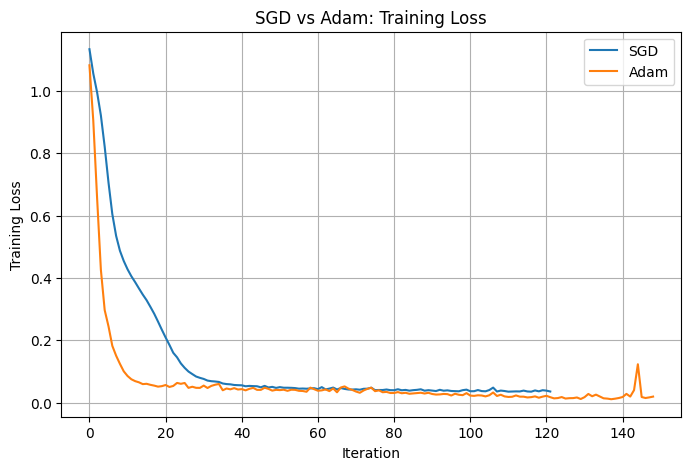

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(sgd_model.loss_curve_, label="SGD")
plt.plot(adam_model.loss_curve_, label="Adam")

plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam: Training Loss")
plt.legend()
plt.grid(True)
plt.show()

## Compare Classification Performance

In [7]:
print("Optimizer Performance")
print("-" * 40)
print(f"SGD  Test Accuracy : {sgd_accuracy:.4f}")
print(f"Adam Test Accuracy : {adam_accuracy:.4f}")

print("\nSGD Classification Report")
print(classification_report(
    y_test,
    sgd_predictions,
    target_names=iris.target_names
))

print("Adam Classification Report")
print(classification_report(
    y_test,
    adam_predictions,
    target_names=iris.target_names
))

Optimizer Performance
----------------------------------------
SGD  Test Accuracy : 0.9667
Adam Test Accuracy : 0.9333

SGD Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Adam Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Compare Final Loss Values

A lower training loss indicates that the neural network is fitting the training data with less error. The test accuracy gives a separate measure of classification performance on unseen data.

In [8]:
print("Final Training Loss")
print("-" * 30)
print(f"SGD  : {sgd_model.loss_curve_[-1]:.6f}")
print(f"Adam : {adam_model.loss_curve_[-1]:.6f}")

Final Training Loss
------------------------------
SGD  : 0.035526
Adam : 0.019149


## Conclusion

Both SGD and Adam can be used to train the same neural network, but their optimization behavior can differ.

### SGD
- Uses stochastic gradient-based updates.
- Momentum can help make training more stable.
- Performance depends strongly on the learning rate and other hyperparameters.

### Adam
- Automatically adapts the learning rate for each parameter.
- Often converges quickly.
- Combines momentum-like behavior with adaptive learning rates.

### Expected Result

After running the notebook, compare:
- Training loss curves
- Number of training iterations
- Final training loss
- Test accuracy
- Precision, recall, and F1-score

The exact numerical results may vary depending on the dataset split and model initialization. The main objective is to observe how changing the optimizer changes the neural network's training behavior and classification performance.